In [1]:
import findspark, pyspark
import pandas as pd
import numpy as np

from pyspark.sql import SparkSession


In [2]:
# Create Spark1 session: we use the following configurations:

# - master("local[*]"): Run Spark locally with as many worker threads as logical cores on your machine.
# - config("spark.driver.memory", "1g"): Allocate 1 GB of memory to the Spark driver.
# - config("spark.executor.memory", "2g"): Allocate 2 GB of memory to each Spark executor.
# - appName("IntroToSpark"): Name the Spark application "IntroToSpark".

spark = (SparkSession.builder
    .master("local[*]")
    .appName("IntroToSpark1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.host", "127.0.0.1")
    # Optional: let Spark pick a free UI port instead of hardcoding 4040
    .config("spark.ui.enabled", "true")
    .config("spark.ui.port", "0")
    .config("spark.driver.memory", "2g")
    .getOrCreate())

sc1 = spark.sparkContext  # To access SparkContext if needed
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
25/12/17 23:01:15 WARN Utils: Your hostname, MacBook-Pro-van-Douwe.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.19 instead (on interface en0)
25/12/17 23:01:15 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/17 23:01:15 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
daily_data = spark.read.parquet('../Cleaned_data/daily_data.parquet')

In [4]:
daily_data.show()

+------+---------------+----+-----+----+-----+--------+--------------------+-------------------+--------------------+--------------------+--------------------+------+--------+---------+-----------+----------------+--------------+---------------+--------------------+--------+
|ticker|Local Date (ET)|Open| High| Low|Close|  Volume|        daily_return|               %Chg|     intraday_return|      intraday_range|                 gap|up_day|down_day|volume_up|volume_down|days_since_start|biweekly_index|biweekly_period|            longName|industry|
+------+---------------+----+-----+----+-----+--------+--------------------+-------------------+--------------------+--------------------+--------------------+------+--------+---------+-----------+----------------+--------------+---------------+--------------------+--------+
|ARG.TO|     2024-01-15|1.36| 1.38|1.35| 1.38| 71200.0|                NULL|               NULL|0.014705882352941025| 0.02205882352941162|                NULL|     1|      

In [5]:
tickers_df = pd.read_csv('../Data/tickers.csv')
tickers_df.head()

,tickers,Company Name
0,ARG.TO,Amerigo Resources Ltd
1,AYA.TO,Aya Gold & Silver Inc
2,CG.TO,Centerra Gold Inc
3,CGC.V,Canadian Gold Corp
4,CKG.V,Chesapeake Gold Corp


In [6]:
maturity_df = pd.read_csv('../Data/Categorical/maturity_level.csv')
maturity_df.head()

,ticker,maturity
0,ARG.TO,Producer
1,AYA.TO,Producer
2,CG.TO,Producer
3,CGC.V,Explorer
4,CKG.V,Explorer


In [7]:
# ---------------------------------
# Merge with dependent variable 
# ---------------------------------
# Load in dependent data
tickers = tickers_df['tickers'].to_list()


dep_df = pd.concat(
    [
        pd.read_csv(
            f'../dependent_data_collection/Data/Dependent_data/{ticker}_announcements.csv'
        )
        for ticker in tickers
    ],
    ignore_index=True
)

# Only keep ticker, date-time and type + filter on rows where type == financing_announcement
dep_df = dep_df[dep_df['type'] == "financing_announcement"][['ticker', 'date-time', 'type']].rename(columns={'date-time': "Local Date (ET)"})

# Make daily_data pandas dataframe
daily_data_pd = daily_data.toPandas()

# merge maturity levels
daily_data_pd = daily_data_pd.merge(maturity_df, on='ticker', how='left')

# Convert date columns in pandas
daily_data_pd['Local Date (ET)'] = pd.to_datetime(daily_data_pd['Local Date (ET)'])

dep_df['Local Date (ET)'] = pd.to_datetime(dep_df['Local Date (ET)'])

# (Optional but usually needed) if one side has time and the other is date-only:
daily_data_pd['Local Date (ET)'] = daily_data_pd['Local Date (ET)'].dt.normalize()
dep_df['Local Date (ET)'] = dep_df['Local Date (ET)'].dt.normalize()

# Merge on date and ticker
df = daily_data_pd.merge(dep_df, on=['ticker', 'Local Date (ET)'], how='left')


In [8]:
# Create a new column 
df['financing_announcement'] = np.where(df['type'] == "financing_announcement", 1, 0)
df.head()

,ticker,Local Date (ET),Open,High,Low,Close,Volume,daily_return,%Chg,intraday_return,...,volume_up,volume_down,days_since_start,biweekly_index,biweekly_period,longName,industry,maturity,type,financing_announcement
0,ARG.TO,2024-01-15,1.36,1.38,1.35,1.38,71200.0,NaN,NaN,0.014706,...,71200.0,NaN,0,0,P0,Amerigo Resources Ltd.,Copper,Producer,NaN,0
1,ARG.TO,2024-01-16,1.32,1.35,1.32,1.35,140200.0,-0.021739,-2.173913,0.022727,...,140200.0,NaN,1,0,P0,Amerigo Resources Ltd.,Copper,Producer,NaN,0
2,ARG.TO,2024-01-17,1.29,1.32,1.28,1.31,292600.0,-0.029630,-2.962963,0.015504,...,292600.0,NaN,2,0,P0,Amerigo Resources Ltd.,Copper,Producer,NaN,0
3,ARG.TO,2024-01-18,1.29,1.32,1.27,1.32,119500.0,0.007634,0.763359,0.023256,...,119500.0,NaN,3,0,P0,Amerigo Resources Ltd.,Copper,Producer,NaN,0
4,ARG.TO,2024-01-19,1.30,1.32,1.28,1.28,123300.0,-0.030303,-3.030303,-0.015385,...,NaN,123300.0,4,0,P0,Amerigo Resources Ltd.,Copper,Producer,NaN,0


# Immediate impact

In [9]:
average_daily_return_fin_days = np.mean(df[df['financing_announcement'] == 1]['daily_return'])
print(f'Average Return On days of financing Announcements: {average_daily_return_fin_days}')

Average Return On days of financing Announcements: -0.01836665016483881


In [10]:
df['industry'].value_counts()

industry
Other Industrial Metals & Mining    1931
Gold                                1529
Other Precious Metals & Mining       787
Copper                               662
Silver                               502
Name: count, dtype: int64

In [11]:
df.columns

Index(['ticker', 'Local Date (ET)', 'Open', 'High', 'Low', 'Close', 'Volume',
       'daily_return', '%Chg', 'intraday_return', 'intraday_range', 'gap',
       'up_day', 'down_day', 'volume_up', 'volume_down', 'days_since_start',
       'biweekly_index', 'biweekly_period', 'longName', 'industry', 'maturity',
       'type', 'financing_announcement'],
      dtype='object')

In [12]:
average_copper = np.mean(df[
    (df['financing_announcement'] == 1) & 
    (df['industry'] == "Copper")
]['daily_return'])
average_gold = np.mean(df[
    (df['financing_announcement'] == 1) & 
    (df['industry'] == "Gold")
]['daily_return'])
average_silver = np.mean(df[
    (df['financing_announcement'] == 1) & 
    (df['industry'] == "Silver ")
]['daily_return'])
average_other_industrial = np.mean(df[
    (df['financing_announcement'] == 1) & 
    (df['industry'] == "Other Industrial Metals & Mining")
]['daily_return'])
average_other_metals = np.mean(df[
    (df['financing_announcement'] == 1) & 
    (df['industry'] == "Other Precious Metals & Mining ")
]['daily_return'])

print(f'Average Return On days of financing Announcements, Copper: {average_copper}')
print(f'Average Return On days of financing Announcements, Gold: {average_gold}')
print(f'Average Return On days of financing Announcements, Silver: {average_silver}')
print(f'Average Return On days of financing Announcements, Other Industrial metals: {average_other_industrial}')
print(f'Average Return On days of financing Announcements, Other Precious Metals: {average_other_metals}')


Average Return On days of financing Announcements, Copper: -0.021047008547008583
Average Return On days of financing Announcements, Gold: -0.021352181228933967
Average Return On days of financing Announcements, Silver: nan
Average Return On days of financing Announcements, Other Industrial metals: -0.0046032423078446166
Average Return On days of financing Announcements, Other Precious Metals: nan


In [13]:
# EXTRA CODE
event_days = df[df['financing_announcement'] == 1]
non_event_days = df[df['financing_announcement'] == 0]

event_days[['daily_return', 'Volume', 'intraday_range']].mean(), \
non_event_days[['daily_return', 'Volume', 'intraday_range']].mean()

from scipy.stats import ttest_ind

ttest_ind(
    event_days['daily_return'].dropna(),
    non_event_days['daily_return'].dropna(),
    equal_var=False
)

TtestResult(statistic=-2.139630938920467, pvalue=0.03819069987948018, df=42.35097476011837)

Interpretation
* The negative t-statistic means:
Average daily returns on financing announcement days are lower than on non-announcement days.
* The p-value (0.038) is below 0.05, so the result is statistically significant at the 5% level.

You reject the null hypothesis of no difference in returns.

# Impact Over Window

In [14]:
df = df.sort_values(['ticker', 'Local Date (ET)'])

df['event_id'] = (
    df
    .groupby('ticker')['financing_announcement']
    .cumsum()
)

df['event_date'] = df['Local Date (ET)'].where(
    df['financing_announcement'] == 1
)

df['event_date'] = (
    df
    .groupby(['ticker', 'event_id'])['event_date']
    .transform('max')
)

df['days_from_event'] = (
    df['Local Date (ET)'] - df['event_date']
).dt.days

event_window = df[
    (df['event_id'] > 0) &
    (df['days_from_event'] >= -5) &
    (df['days_from_event'] <= 10)
].copy()

In [15]:
event_window.head(20)

,ticker,Local Date (ET),Open,High,Low,Close,Volume,daily_return,%Chg,intraday_return,...,biweekly_index,biweekly_period,longName,industry,maturity,type,financing_announcement,event_id,event_date,days_from_event
554,AYA.TO,2025-05-12,10.03,10.20,9.590,9.700,1076300.0,-0.045276,-4.527559,-0.032901,...,34,P34,Aya Gold & Silver Inc.,Silver,Producer,financing_announcement,1,1,2025-05-12,0.0
555,AYA.TO,2025-05-13,11.24,11.75,10.720,10.910,2463000.0,0.124742,12.474227,-0.029359,...,34,P34,Aya Gold & Silver Inc.,Silver,Producer,NaN,0,1,2025-05-12,1.0
556,AYA.TO,2025-05-14,10.42,11.06,10.410,10.950,1189500.0,0.003666,0.366636,0.050864,...,34,P34,Aya Gold & Silver Inc.,Silver,Producer,NaN,0,1,2025-05-12,2.0
557,AYA.TO,2025-05-15,10.59,10.67,10.330,10.630,595200.0,-0.029224,-2.922374,0.003777,...,34,P34,Aya Gold & Silver Inc.,Silver,Producer,NaN,0,1,2025-05-12,3.0
558,AYA.TO,2025-05-16,10.35,10.40,10.060,10.250,1576600.0,-0.035748,-3.574788,-0.009662,...,34,P34,Aya Gold & Silver Inc.,Silver,Producer,NaN,0,1,2025-05-12,4.0
559,AYA.TO,2025-05-20,11.08,11.09,10.480,10.580,1325400.0,0.032195,3.219512,-0.045126,...,35,P35,Aya Gold & Silver Inc.,Silver,Producer,NaN,0,1,2025-05-12,8.0
560,AYA.TO,2025-05-21,11.69,11.89,11.200,11.290,1377100.0,0.067108,6.710775,-0.034217,...,35,P35,Aya Gold & Silver Inc.,Silver,Producer,NaN,0,1,2025-05-12,9.0
561,AYA.TO,2025-05-22,11.30,11.66,11.240,11.650,892700.0,0.031887,3.188663,0.030973,...,35,P35,Aya Gold & Silver Inc.,Silver,Producer,NaN,0,1,2025-05-12,10.0
574,AYA.TO,2025-06-10,14.52,14.91,14.400,14.730,821100.0,0.035501,3.550088,0.014463,...,36,P36,Aya Gold & Silver Inc.,Silver,Producer,financing_announcement,1,2,2025-06-10,0.0
575,AYA.TO,2025-06-11,13.19,13.73,13.060,13.460,3149400.0,-0.086219,-8.621860,0.020470,...,36,P36,Aya Gold & Silver Inc.,Silver,Producer,financing_announcement,1,3,2025-06-11,0.0


In [16]:
# Compute mean return by event time
event_window.groupby('days_from_event')['daily_return'].mean().reset_index()


,days_from_event,daily_return
0,0.0,-0.018367
1,1.0,-0.004821
2,2.0,0.010280
3,3.0,0.003663
4,4.0,0.008970
5,5.0,0.015398
6,6.0,-0.004226
7,7.0,-0.000453
8,8.0,0.022780
9,9.0,0.006418


In [17]:
# Compute CAR = Cumulative abnormal returns
car = (
    event_window
    .groupby(['ticker', 'event_date'])['daily_return']
    .sum()
    .reset_index(name='CAR')
)

car['CAR'].describe()

count    43.000000
mean      0.009846
std       0.123496
min      -0.278203
25%      -0.066545
50%      -0.011905
75%       0.057865
max       0.385531
Name: CAR, dtype: float64

Average effect
* The mean CAR is negative (−0.41%)
* This confirms your t-test result:
Financing announcements tend to destroy shareholder value on average

However…

Distribution is wide
* Large heterogeneity across firms
* Some announcements lead to very negative outcomes
* Others are strongly positive

This implies:
* Market reaction depends on context (firm size, industry, type of financing)

Average effect
* The mean CAR is negative (−0.41%)
* This confirms your t-test result:
Financing announcements tend to destroy shareholder value on average

However…

Distribution is wide
* Large heterogeneity across firms
* Some announcements lead to very negative outcomes
* Others are strongly positive

This implies:
* Market reaction depends on context (firm size, industry, type of financing)

In [18]:
car_firms = (
    event_window
    .groupby(['ticker', 'event_date'])['daily_return']
    .sum()
    .reset_index(name='CAR')
)

car_firms.head()

,ticker,event_date,CAR
0,AYA.TO,2025-05-12,0.149351
1,AYA.TO,2025-06-10,0.035501
2,AYA.TO,2025-06-11,-0.101820
3,AYA.TO,2025-06-13,-0.042402
4,CG.TO,2024-11-05,-0.071779


In [19]:
car_by_day = (
    event_window
    .groupby('days_from_event')['daily_return']
    .agg(
        mean_return='mean',
        std_return='std',
        n='count'
    )
    .reset_index()
)

# Cumulative average return
car_by_day['CAR'] = car_by_day['mean_return'].cumsum()

car_by_day.head(10)

,days_from_event,mean_return,std_return,n,CAR
0,0.0,-0.018367,0.064844,43,-0.018367
1,1.0,-0.004821,0.096788,26,-0.023187
2,2.0,0.010280,0.053580,19,-0.012907
3,3.0,0.003663,0.029902,21,-0.009244
4,4.0,0.008970,0.046591,21,-0.000274
5,5.0,0.015398,0.038365,18,0.015124
6,6.0,-0.004226,0.060008,24,0.010898
7,7.0,-0.000453,0.045454,29,0.010445
8,8.0,0.022780,0.058452,24,0.033225
9,9.0,0.006418,0.052038,18,0.039644


In [20]:
# CAR by event time per company
# mean return at each event day per company, then cumulative
car_by_day_company = (
    event_window
    .groupby(['ticker', 'days_from_event'], as_index=False)['daily_return']
    .mean()
    .sort_values(['ticker', 'days_from_event'])
)

car_by_day_company['CAR'] = car_by_day_company.groupby('ticker')['daily_return'].cumsum()

car_by_day_company.head(10)

,ticker,days_from_event,daily_return,CAR
0,AYA.TO,0.0,-0.023998,-0.023998
1,AYA.TO,1.0,0.054570,0.030572
2,AYA.TO,2.0,0.003666,0.034238
3,AYA.TO,3.0,-0.013480,0.020758
4,AYA.TO,4.0,-0.021451,-0.000692
5,AYA.TO,5.0,0.009480,0.008788
6,AYA.TO,6.0,-0.017280,-0.008492
7,AYA.TO,7.0,-0.032875,-0.041367
8,AYA.TO,8.0,0.032195,-0.009172
9,AYA.TO,9.0,0.067108,0.057936


In [21]:
# CAR by event time per industry
car_by_day_industry = (
    event_window
    .groupby(['industry', 'days_from_event'], as_index=False)['daily_return']
    .mean()
    .sort_values(['industry', 'days_from_event'])
)

car_by_day_industry['CAR'] = car_by_day_industry.groupby('industry')['daily_return'].cumsum()

car_by_day_industry.head(10)

,industry,days_from_event,daily_return,CAR
0,Copper,0.0,-0.021047,-0.021047
1,Copper,1.0,0.165217,0.144170
2,Copper,2.0,-0.089552,0.054618
3,Copper,3.0,0.000000,0.054618
4,Copper,6.0,0.008197,0.062815
5,Copper,7.0,0.000000,0.062815
6,Copper,8.0,-0.016260,0.046555
7,Copper,9.0,-0.016529,0.030026
8,Copper,10.0,-0.008403,0.021622
9,Gold,0.0,-0.021352,-0.021352


In [22]:
# CAR by event time per maturity
car_by_day_maturity = (
    event_window
    .groupby(['maturity', 'days_from_event'], as_index=False)['daily_return']
    .mean()
    .sort_values(['maturity', 'days_from_event'])
)

car_by_day_maturity['CAR'] = (
    car_by_day_maturity
    .groupby('maturity')['daily_return']
    .cumsum()
)

car_by_day_maturity.head(10)

,maturity,days_from_event,daily_return,CAR
0,Developer,0.0,-0.009399,-0.009399
1,Developer,1.0,0.013373,0.003974
2,Developer,2.0,-0.042465,-0.038491
3,Developer,3.0,-0.002244,-0.040736
4,Developer,4.0,-0.001844,-0.042580
5,Developer,5.0,-0.005000,-0.047580
6,Developer,6.0,-0.004983,-0.052562
7,Developer,7.0,0.009922,-0.042640
8,Developer,8.0,-0.009165,-0.051805
9,Developer,9.0,-0.009298,-0.061103


In [32]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.lines import Line2D

def plot_simple_car(
    df,
    car_by_day,
    group_col,
    x_col="days_from_event",
    y_col="CAR",
    title=None,
    figsize=(10, 6),
    main_color="#1f4e79",        # dark navy (average CAR)
    palette=None,               # blue-gray palette for groups
    max_groups_for_labels=6
):
    """
    Simple CAR plot with cohesive blue-gray colors:
    - group lines: different blue-gray shades
    - average CAR: dark navy
    """

    if palette is None:
        palette = [
            "#4d4dd0",  # steel blue
            "#3c79d6",
            "#65abd7",
            "#8faec2",
            "#9fbfd1",
            "#aecfe0",
        ]

    d = df[[group_col, x_col, y_col]].dropna().copy()
    d = d.sort_values([group_col, x_col])
    groups = list(d[group_col].unique())

    plt.figure(figsize=figsize)

    # ---- Group lines ----
    if len(groups) <= max_groups_for_labels:
        for i, (g, gdf) in enumerate(d.groupby(group_col)):
            plt.plot(
                gdf[x_col],
                gdf[y_col],
                linewidth=2,
                alpha=0.9,
                color=palette[i % len(palette)],
                label=str(g)
            )
    else:
        # many groups → subtle variation, same family
        for i, (_, gdf) in enumerate(d.groupby(group_col)):
            plt.plot(
                gdf[x_col],
                gdf[y_col],
                linewidth=2,
                alpha=0.75,
                color=palette[i % len(palette)]
            )

    # ---- Average CAR (darkest line) ----
    plt.plot(
        car_by_day['days_from_event'],
        car_by_day['CAR'],
        linewidth=3,
        color=main_color,
        label="Average CR"
    )

    # ---- Reference lines ----
    plt.axvline(0, linestyle="--", linewidth=1.2, color=main_color)
    plt.axhline(0, linewidth=1.2, color="black")

    # Labels & title
    plt.xlabel("Time of Financing Event", fontsize = 12)
    plt.ylabel("Cumulative Return (CR)", fontsize = 12)
    plt.title(title or f"CAR around financing announcements ({group_col})",pad=12,  fontsize = 16)

    # Clean axes
    ax = plt.gca()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ---- Legend ----
    if len(groups) <= max_groups_for_labels:
        plt.legend(frameon=False, loc="upper left")
    else:
        legend_elements = [
            Line2D([0], [0], color=palette[0], lw=4, label=f"Individual {group_col}s"),
            Line2D([0], [0], color=main_color, lw=4, label="Average CAR"),
            Line2D([0], [0], color=main_color, lw=2, linestyle="--", label="Event date"),
        ]
        plt.legend(handles=legend_elements, frameon=False, loc="upper left")

    plt.tight_layout()
    plt.show()

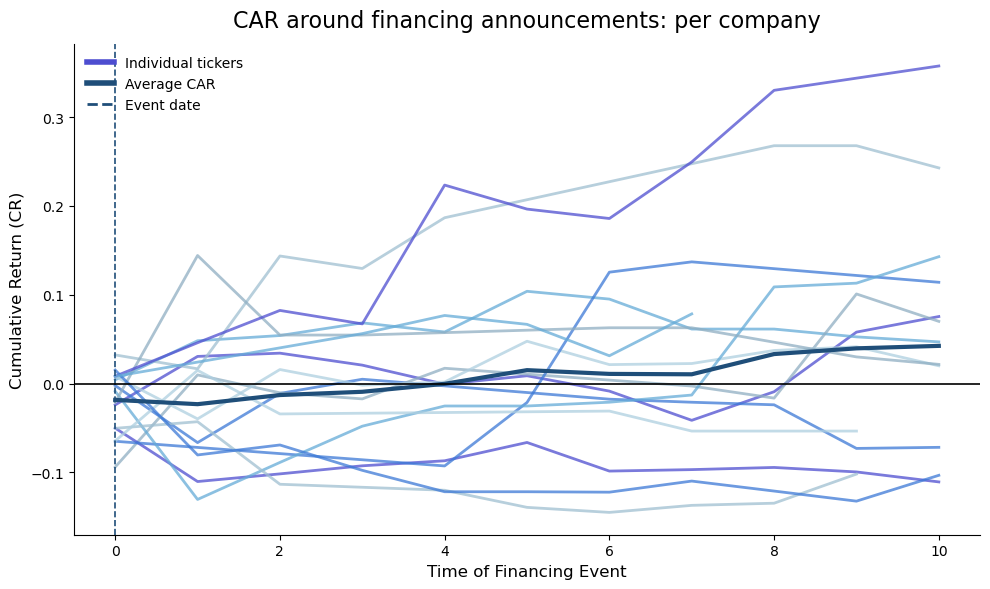

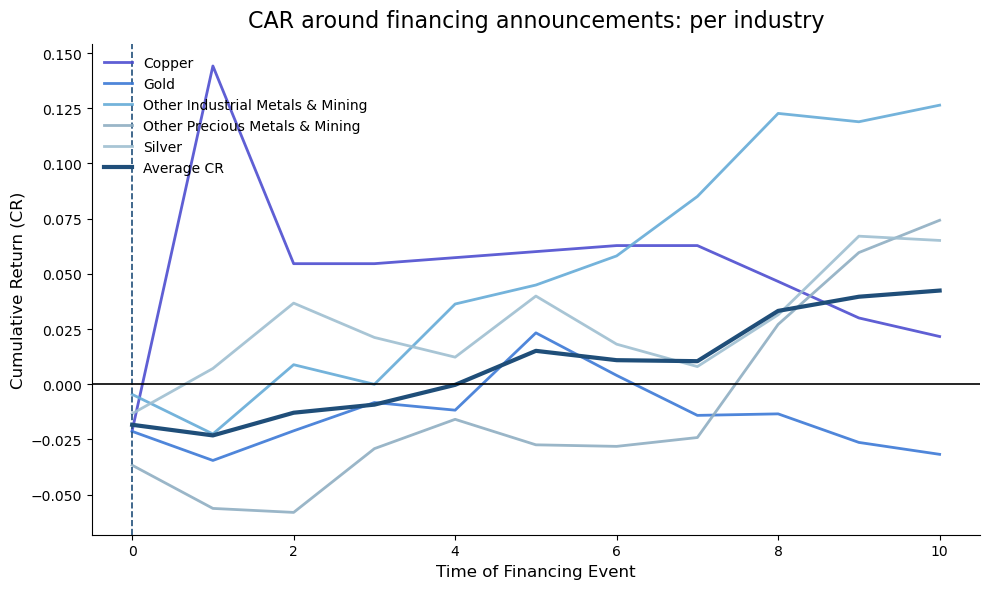

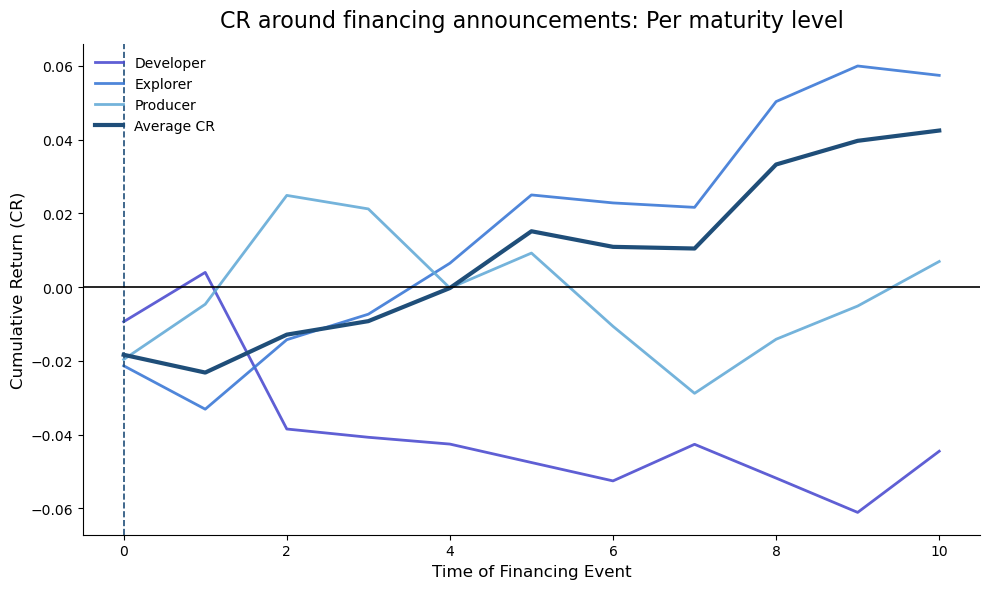

In [33]:
plot_simple_car(
    car_by_day_company,
    car_by_day,
    group_col="ticker",
    title="CAR around financing announcements: per company"
)

plot_simple_car(
    car_by_day_industry,
    car_by_day,
    group_col="industry",
    title="CAR around financing announcements: per industry"
)

plot_simple_car(
    car_by_day_maturity,
    car_by_day,
    group_col="maturity",
    title="CR around financing announcements: Per maturity level"
)

In [224]:
import statsmodels.formula.api as smf

model = smf.ols(
    'daily_return ~ financing_announcement + Volume + intraday_range + C(ticker)',
    data=df
).fit(cov_type='HC3')

model.summary()

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 21, but rank is 20
  warnings.warn('covariance of constraints does not have full '


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           daily_return   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.010
Method:                 Least Squares   F-statistic:                     1.010
Date:                Wed, 17 Dec 2025   Prob (F-statistic):              0.446
Time:                        18:02:02   Log-Likelihood:                 8347.8
No. Observations:                5109   AIC:                        -1.665e+04
Df Residuals:                    5087   BIC:                        -1.651e+04
Df Model:                          21                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0.0030      0.002     -1.549      0.121      -0.007       0.001
C(ticker)[T.AYA.TO]       -0.0047      0.003     -1.478      0.140      -0.011       0.002
C(ticker)[T.CG.TO]      2.932e-05      0.002      0.014      0.989      -0.004       0.004
C(ticker)[T.CGC.V]         0.0017      0.003      0.534      0.594      -0.005       0.008
C(ticker)[T.CKG.V]        -0.0013      0.004     -0.314      0.753      -0.010       0.007
C(ticker)[T.DMX.V]        -0.0007      0.003     -0.214      0.830      -0.007       0.005
C(ticker)[T.DV.V]         -0.0018      0.003     -0.676      0.499      -0.007       0.003
C(ticker)[T.EDG.V]         0.0016      0.004      0.453      0.650      -0.005       0.009
C(ticker)[T.ELO.TO]       -0.0046      0.003     -1.578      0.115      -0.010       0.001
C(ticker)[T.EQX]          -0.0402      0.019     -2.167      0.030      -0.077      -0.004
C(ticker)[T.ESK.V]        -0.0020      0.004     -0.498      0.618      -0.010       0.006
C(ticker)[T.FAS.V]        -0.0008      0.007     -0.111      0.911      -0.015       0.014
C(ticker)[T.FDY.TO]        0.0010      0.002      0.431      0.666      -0.004       0.006
C(ticker)[T.FINX.V]        0.0017      0.008      0.209      0.834      -0.014       0.018
C(ticker)[T.FNM.V]        -0.0027      0.003     -0.974      0.330      -0.008       0.003
C(ticker)[T.FOM.TO]       -0.0032      0.002     -1.421      0.155      -0.008       0.001
C(ticker)[T.FURY.TO]      -0.0004      0.002     -0.171      0.864      -0.005       0.004
C(ticker)[T.FVL.TO]       -0.0006      0.002     -0.259      0.796      -0.005       0.004
C(ticker)[T.FWZ.V]         0.0008      0.002      0.397      0.691      -0.003       0.005
financing_announcement    -0.0237      0.010     -2.310      0.021      -0.044      -0.004
Volume                  1.973e-09   1.24e-09      1.585      0.113   -4.67e-10    4.41e-09
intraday_range             0.1251      0.048      2.631      0.009       0.032       0.218
==============================================================================
Omnibus:                     1004.575   Durbin-Watson:                   2.260
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            16840.234
Skew:                           0.465   Prob(JB):                         0.00
Kurtosis:                      11.846   Cond. No.                     3.11e+07
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 3.11e+07. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [161]:
print(df.groupby('financing_announcement')['intraday_return'].mean())
print(df.groupby('financing_announcement')['intraday_range'].mean())
print(df.groupby('financing_announcement')['Volume'].mean())

financing_announcement
0    0.002122
1    0.000281
Name: intraday_return, dtype: float64
financing_announcement
0    0.050350
1    0.069823
Name: intraday_range, dtype: float64
financing_announcement
0    788608.081595
1    565636.627907
Name: Volume, dtype: float64


# Make use of the biweekly returns of the commodities and sectors

In [168]:
# biweekly data
df = spark.read.parquet('../Cleaned_data/biweekly_basetable_w_sentiment_5.parquet')
df.show()

25/12/17 17:40:22 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+--------+---------------+--------------+------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+--------+--------------------+-------------------------+-------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+----------------------------------+---------------------------------+--------------------+-------------------+------------------+---------+---------

In [162]:
# Import sector tracker and commodities data
commodities_df = spark.read.parquet('../Cleaned_data/biweekly_master_commodity_tracker.parquet').toPandas()
sector_df = spark.read.parquet('../Cleaned_data/biweekly_master_sector_tracker.parquet').toPandas()

commodities_df.head()


,biweekly_period,gold_ret,silver_ret,platinum_ret,palladium_ret,copper_ret,commodity_tracker
0,P0,-0.0045,-0.0078,0.0181,0.0254,0.0223,0.01070
1,P1,-0.0009,-0.0264,-0.0616,-0.1113,-0.0483,-0.04970
2,P10,-0.0065,-0.0404,-0.0621,-0.0245,-0.0269,-0.03208
3,P11,0.0066,-0.0030,0.0352,0.1067,-0.0290,0.02330
4,P12,0.0392,0.0522,0.0008,-0.0501,0.0382,0.01606


In [116]:
sector_df.head()

,biweekly_period,sector_ret,junior_sector_ret,sector_tracker
0,P0,-0.0113,-0.0153,-0.01330
1,P1,-0.0490,-0.0517,-0.05035
2,P10,-0.0591,-0.0712,-0.06515
3,P11,0.0220,0.0152,0.01860
4,P12,0.1220,0.1307,0.12635
